<a href="https://colab.research.google.com/github/Hithavan31/BIS_PROGRAMS/blob/main/1BM24CS118_Medical_Image_Segmentation_Grey_wolf_Optimization_Algorithm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload TWO files:
1. MRI/CT image
2. Reference segmentation mask


Saving reference_mask.png to reference_mask (1).png
Saving mri_image.png to mri_image (1).png

Images loaded successfully!
Image dimensions: (795, 887)
Reference dimensions: (795, 887)
ROI pixels: 21661

========== BRIGHT ROI OPTIMIZATION ==========
Iteration 01/50 | Threshold: 126.14 | Dice: 0.5135
Iteration 02/50 | Threshold: 122.31 | Dice: 0.5140
Iteration 03/50 | Threshold: 122.31 | Dice: 0.5140
Iteration 04/50 | Threshold: 122.31 | Dice: 0.5140
Iteration 05/50 | Threshold: 122.31 | Dice: 0.5140
Iteration 06/50 | Threshold: 118.78 | Dice: 0.5144
Iteration 07/50 | Threshold: 118.78 | Dice: 0.5144
Iteration 08/50 | Threshold: 119.99 | Dice: 0.5148
Iteration 09/50 | Threshold: 119.99 | Dice: 0.5148
Iteration 10/50 | Threshold: 119.99 | Dice: 0.5148
Iteration 11/50 | Threshold: 119.99 | Dice: 0.5148
Iteration 12/50 | Threshold: 119.99 | Dice: 0.5148
Iteration 13/50 | Threshold: 119.99 | Dice: 0.5148
Iteration 14/50 | Threshold: 119.99 | Dice: 0.5148
Iteration 15/50 | Threshold: 119.99 

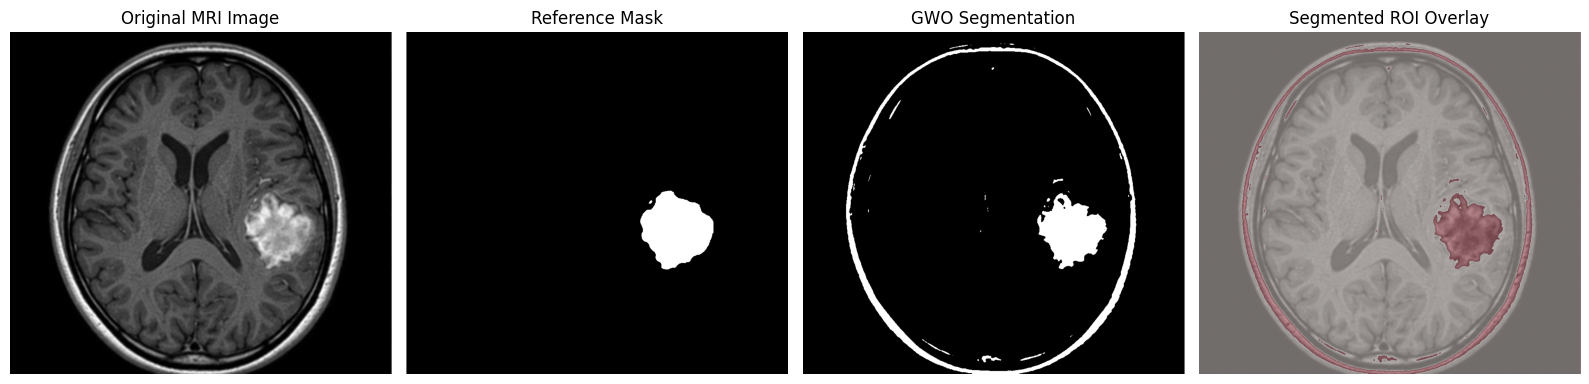

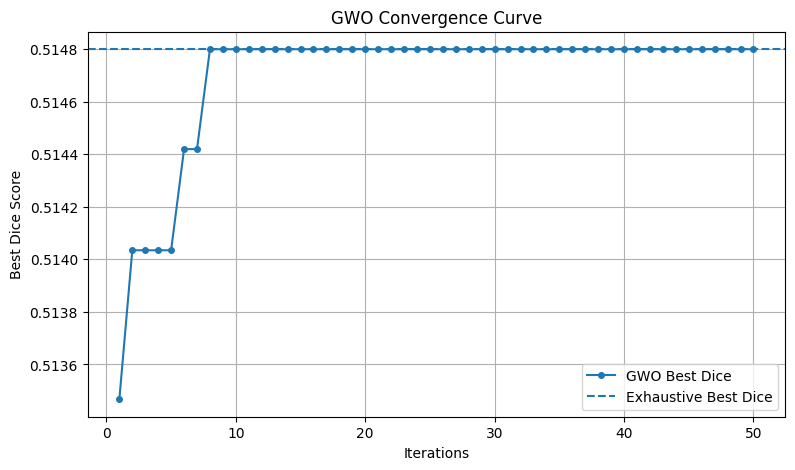


Segmentation image saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:

# ============================================================
# MEDICAL IMAGE SEGMENTATION USING GREY WOLF OPTIMIZER (GWO)
# ============================================================

import numpy as np
import cv2
import matplotlib.pyplot as plt
from google.colab import files

# ============================================================
# 1. UPLOAD MRI IMAGE AND REFERENCE MASK
# ============================================================

print("Upload TWO files:")
print("1. MRI/CT image")
print("2. Reference segmentation mask")

uploaded = files.upload()

file_names = list(uploaded.keys())

if len(file_names) < 2:
    raise ValueError("Please upload both images.")

# Identify files using their names
mask_candidates = [
    f for f in file_names
    if "mask" in f.lower() or "reference" in f.lower()
]

if mask_candidates:
    mask_name = mask_candidates[0]
    image_name = next(f for f in file_names if f != mask_name)
else:
    image_name = file_names[0]
    mask_name = file_names[1]

# Read images
image = cv2.imdecode(
    np.frombuffer(uploaded[image_name], np.uint8),
    cv2.IMREAD_GRAYSCALE
)

mask = cv2.imdecode(
    np.frombuffer(uploaded[mask_name], np.uint8),
    cv2.IMREAD_GRAYSCALE
)

if image is None or mask is None:
    raise ValueError("Unable to read uploaded images.")

# Resize mask if necessary
if image.shape != mask.shape:
    mask = cv2.resize(
        mask,
        (image.shape[1], image.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

# Convert reference mask to binary
reference = mask > 127

# Light image smoothing
image = cv2.GaussianBlur(image, (3, 3), 0)

print("\nImages loaded successfully!")
print("Image dimensions:", image.shape)
print("Reference dimensions:", reference.shape)
print("ROI pixels:", np.sum(reference))


# ============================================================
# 2. INITIALIZE GWO PARAMETERS
# ============================================================

N = 20                 # Number of wolves
MaxIter = 50           # Maximum iterations

lower_bound = 1
upper_bound = 254

# ============================================================
# 3. DICE SCORE AND FITNESS FUNCTION
# ============================================================

def dice_score(predicted, reference):

    intersection = np.sum(predicted & reference)

    denominator = np.sum(predicted) + np.sum(reference)

    return (2 * intersection + 1e-8) / (
        denominator + 1e-8
    )


def fitness_function(threshold, bright):

    threshold = int(np.clip(
        round(threshold),
        lower_bound,
        upper_bound
    ))

    if bright:
        predicted = image >= threshold
    else:
        predicted = image <= threshold

    dice = dice_score(predicted, reference)

    # GWO minimizes the fitness value
    return 1 - dice


# ============================================================
# 4. GREY WOLF OPTIMIZATION FUNCTION
# ============================================================

def run_gwo(bright):

    # Initialize wolves with distributed thresholds
    wolves = np.linspace(
        lower_bound,
        upper_bound,
        N
    )

    np.random.shuffle(wolves)

    # Add random variation
    wolves = np.clip(
        wolves + np.random.uniform(-8, 8, N),
        lower_bound,
        upper_bound
    )

    best_position = 0
    best_fitness = float("inf")

    history = []

    # GWO iterations
    for iteration in range(MaxIter):

        # Evaluate all wolves
        fitness_values = np.array([
            fitness_function(w, bright)
            for w in wolves
        ])

        # Rank current population
        sorted_indices = np.argsort(fitness_values)

        alpha_pos = wolves[sorted_indices[0]]
        beta_pos = wolves[sorted_indices[1]]
        delta_pos = wolves[sorted_indices[2]]

        alpha_score = fitness_values[sorted_indices[0]]

        # Preserve global best solution
        if alpha_score < best_fitness:

            best_fitness = alpha_score
            best_position = alpha_pos

        # Record best Dice score
        history.append(1 - best_fitness)

        # Adaptive parameter decreases from 2 to 0
        a = 2 - 2 * iteration / (MaxIter - 1)

        new_wolves = np.zeros(N)

        # Update every wolf
        for i in range(N):

            X = wolves[i]

            # Alpha calculations
            r1, r2 = np.random.random(2)

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(C1 * alpha_pos - X)

            X1 = alpha_pos - A1 * D_alpha

            # Beta calculations
            r1, r2 = np.random.random(2)

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(C2 * beta_pos - X)

            X2 = beta_pos - A2 * D_beta

            # Delta calculations
            r1, r2 = np.random.random(2)

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(C3 * delta_pos - X)

            X3 = delta_pos - A3 * D_delta

            # Update wolf position
            new_wolves[i] = (X1 + X2 + X3) / 3

        # Keep positions within threshold range
        wolves = np.clip(
            new_wolves,
            lower_bound,
            upper_bound
        )

        # Preserve best solution (elitism)
        wolves[0] = best_position

        print(
            f"Iteration {iteration + 1:02d}/{MaxIter} | "
            f"Threshold: {best_position:.2f} | "
            f"Dice: {1 - best_fitness:.4f}"
        )

    return best_position, best_fitness, history


# ============================================================
# 5. RUN GWO FOR BRIGHT AND DARK ROI
# ============================================================

print("\n========== BRIGHT ROI OPTIMIZATION ==========")

bright_result = run_gwo(True)

print("\n========== DARK ROI OPTIMIZATION ==========")

dark_result = run_gwo(False)

# Select the better GWO solution
if bright_result[1] <= dark_result[1]:

    gwo_threshold = bright_result[0]
    gwo_fitness = bright_result[1]
    gwo_history = bright_result[2]
    roi_type = "Bright"

else:

    gwo_threshold = dark_result[0]
    gwo_fitness = dark_result[1]
    gwo_history = dark_result[2]
    roi_type = "Dark"

print("\nBest GWO ROI type:", roi_type)


# ============================================================
# 6. VALIDATE OPTIMAL THRESHOLD
# ============================================================

print("\n========== THRESHOLD VALIDATION ==========")

best_exact_dice = -1
best_exact_threshold = 0
best_exact_type = ""

# Test every possible integer threshold
for bright in [True, False]:

    for threshold in range(1, 255):

        if bright:
            predicted = image >= threshold
            current_type = "Bright"
        else:
            predicted = image <= threshold
            current_type = "Dark"

        score = dice_score(predicted, reference)

        if score > best_exact_dice:

            best_exact_dice = score
            best_exact_threshold = threshold
            best_exact_type = current_type

# Compare GWO and exhaustive validation
if gwo_fitness <= 1 - best_exact_dice:

    optimal_threshold = int(round(gwo_threshold))
    optimal_type = roi_type
    final_dice = 1 - gwo_fitness

else:

    optimal_threshold = best_exact_threshold
    optimal_type = best_exact_type
    final_dice = best_exact_dice

print("GWO Threshold:", round(gwo_threshold, 2))
print("GWO Dice Score:", round(1 - gwo_fitness, 5))

print("Validated Threshold:", best_exact_threshold)
print("Validated Dice Score:", round(best_exact_dice, 5))

print("\nSelected Optimal Threshold:", optimal_threshold)
print("Selected ROI Type:", optimal_type)


# ============================================================
# 7. GENERATE FINAL SEGMENTATION
# ============================================================

if optimal_type == "Bright":

    final_segmentation = image >= optimal_threshold

else:

    final_segmentation = image <= optimal_threshold

final_dice = dice_score(
    final_segmentation,
    reference
)


# ============================================================
# 8. PERFORMANCE EVALUATION
# ============================================================

TP = np.sum(final_segmentation & reference)

FP = np.sum(final_segmentation & ~reference)

FN = np.sum(~final_segmentation & reference)

TN = np.sum(~final_segmentation & ~reference)

IoU = TP / (TP + FP + FN + 1e-8)

Sensitivity = TP / (TP + FN + 1e-8)

Specificity = TN / (TN + FP + 1e-8)

Accuracy = (TP + TN) / (
    TP + TN + FP + FN + 1e-8
)

print("\n========== FINAL GWO RESULTS ==========")

print("Optimal Threshold :", optimal_threshold)

print("ROI Type          :", optimal_type)

print("Dice Score        :", round(final_dice, 5))

print("IoU Score         :", round(IoU, 5))

print("Sensitivity       :", round(Sensitivity, 5))

print("Specificity       :", round(Specificity, 5))

print("Accuracy          :", round(Accuracy, 5))


# ============================================================
# 9. DISPLAY IMAGE SEGMENTATION RESULTS
# ============================================================

plt.figure(figsize=(16, 5))

plt.subplot(1, 4, 1)

plt.imshow(image, cmap="gray")

plt.title("Original MRI Image")

plt.axis("off")


plt.subplot(1, 4, 2)

plt.imshow(reference, cmap="gray")

plt.title("Reference Mask")

plt.axis("off")


plt.subplot(1, 4, 3)

plt.imshow(final_segmentation, cmap="gray")

plt.title("GWO Segmentation")

plt.axis("off")


plt.subplot(1, 4, 4)

plt.imshow(image, cmap="gray")

plt.imshow(
    final_segmentation,
    cmap="Reds",
    alpha=0.45
)

plt.title("Segmented ROI Overlay")

plt.axis("off")

plt.tight_layout()

plt.show()


# ============================================================
# 10. GWO CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, MaxIter + 1),
    gwo_history,
    marker="o",
    markersize=4,
    label="GWO Best Dice"
)

plt.axhline(
    best_exact_dice,
    linestyle="--",
    label="Exhaustive Best Dice"
)

plt.xlabel("Iterations")

plt.ylabel("Best Dice Score")

plt.title("GWO Convergence Curve")

plt.legend()

plt.grid(True)

plt.show()


# ============================================================
# 11. SAVE AND DOWNLOAD SEGMENTATION
# ============================================================

output_mask = (
    final_segmentation.astype(np.uint8) * 255
)

cv2.imwrite(
    "GWO_Segmented_Image.png",
    output_mask
)

print("\nSegmentation image saved successfully!")

files.download("GWO_Segmented_Image.png")
